In [1]:
import os, sys
sys.path.insert(0, "../src")          # so we can import our own metrics.py

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from metrics import si_sdr, match_sources

os.makedirs("../outputs/figures", exist_ok=True)
SR = 16000
names = ["Speech", "Music", "Ambient"]
plt.rcParams["figure.dpi"] = 110

In [2]:
S     = np.load("../data/mixed/S_true.npy")
A     = np.load("../data/mixed/A_true.npy")
X     = np.load("../data/mixed/X_mixed.npy")
Xc    = np.load("../data/mixed/X_centered.npy")
Z     = np.load("../data/mixed/Z_white.npy")
S_est = np.load("../outputs/separated/S_est.npy")

T = S.shape[1]
t = np.arange(T) / SR
S_plot = S - S.mean(axis=1, keepdims=True)      # centered, like the estimates

# Resolve permutation + sign + scale so estimates are comparable to the sources
order = match_sources(S_est, S)
S_aligned = np.zeros_like(S_est)
for j in range(3):
    e = S_est[order[j]]
    e = np.sign(np.corrcoef(e, S[j])[0, 1]) * e          # fix sign
    S_aligned[j] = e / e.std() * S_plot[j].std()         # fix scale (for plotting only)

print("S", S.shape, "| A", A.shape, "| estimate order:", order)

S (3, 160000) | A (3, 3) | estimate order: [0 1 2]


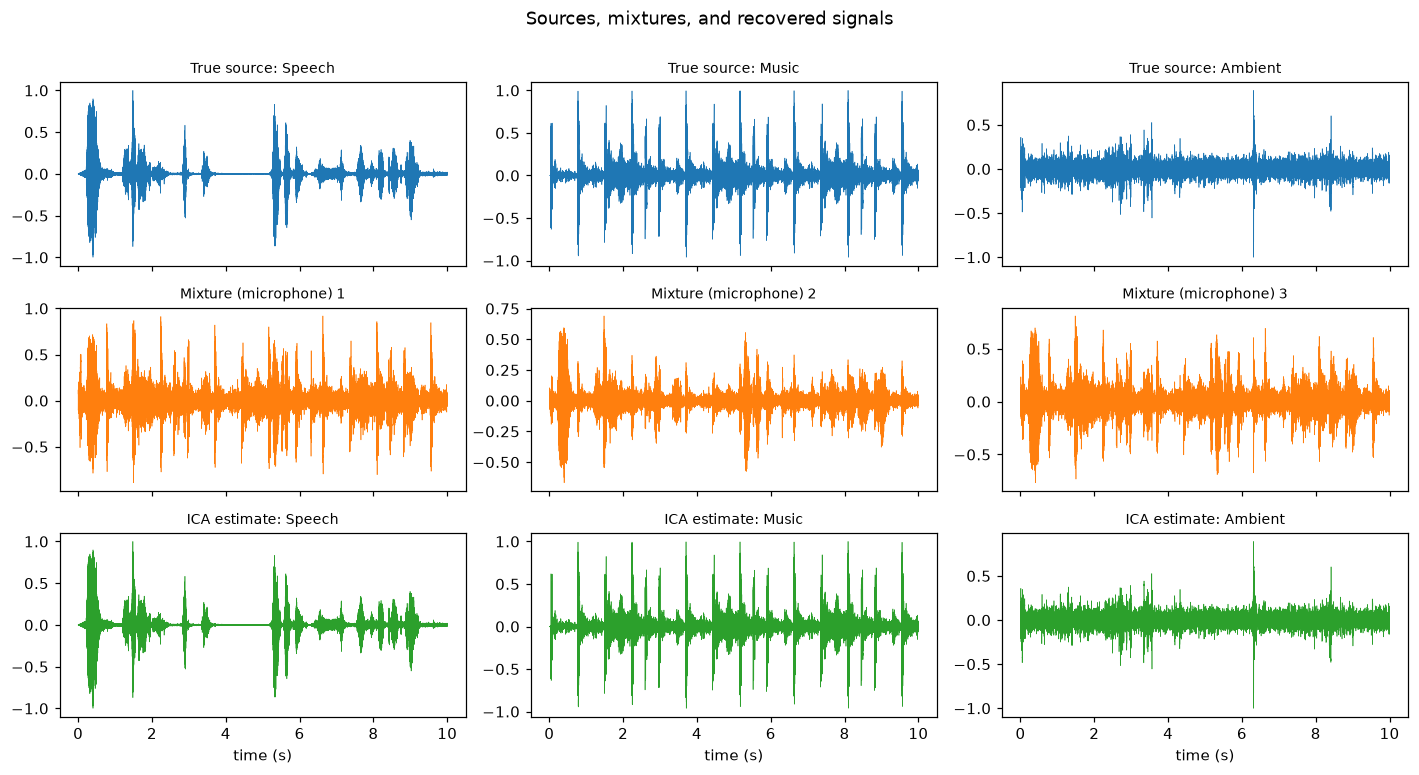

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(13, 7), sharex=True)
rows = [("True source", S_plot), ("Mixture (microphone)", X - X.mean(axis=1, keepdims=True)),
        ("ICA estimate", S_aligned)]
for r, (title, data) in enumerate(rows):
    for c in range(3):
        axes[r, c].plot(t, data[c], lw=0.4, color=["C0", "C1", "C2"][r])
        axes[r, c].set_title(f"{title} {c+1}" if r == 1 else f"{title}: {names[c]}", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
plt.suptitle("Sources, mixtures, and recovered signals", y=1.0)
plt.tight_layout()
plt.savefig("../outputs/figures/waveforms.png", bbox_inches="tight")
plt.show()

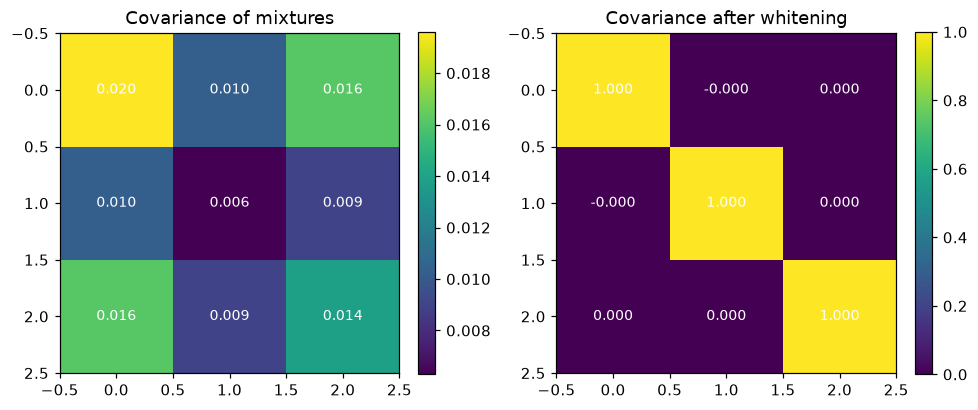

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M, title in [(axes[0], np.cov(Xc), "Covariance of mixtures"),
                     (axes[1], np.cov(Z),  "Covariance after whitening")]:
    im = ax.imshow(M, cmap="viridis")
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", color="w", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig("../outputs/figures/covariance.png", bbox_inches="tight")
plt.show()

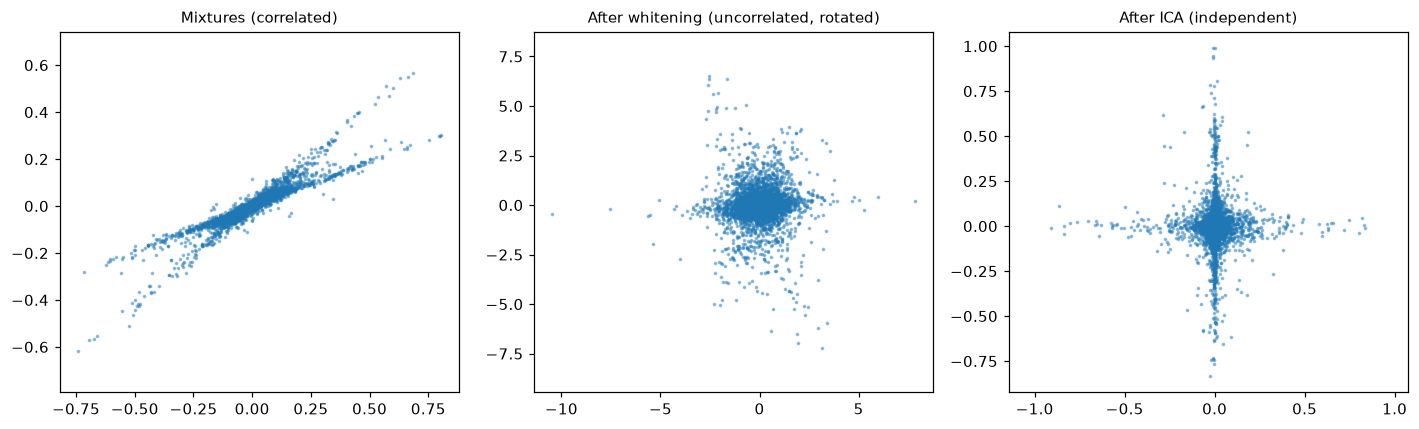

In [5]:
idx = slice(0, T, 40)    # subsample for a clean scatter
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, D, title in [(axes[0], Xc,    "Mixtures (correlated)"),
                     (axes[1], Z,     "After whitening (uncorrelated, rotated)"),
                     (axes[2], S_aligned, "After ICA (independent)")]:
    ax.scatter(D[0, idx], D[1, idx], s=2, alpha=0.4)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.savefig("../outputs/figures/scatter.png", bbox_inches="tight")
plt.show()

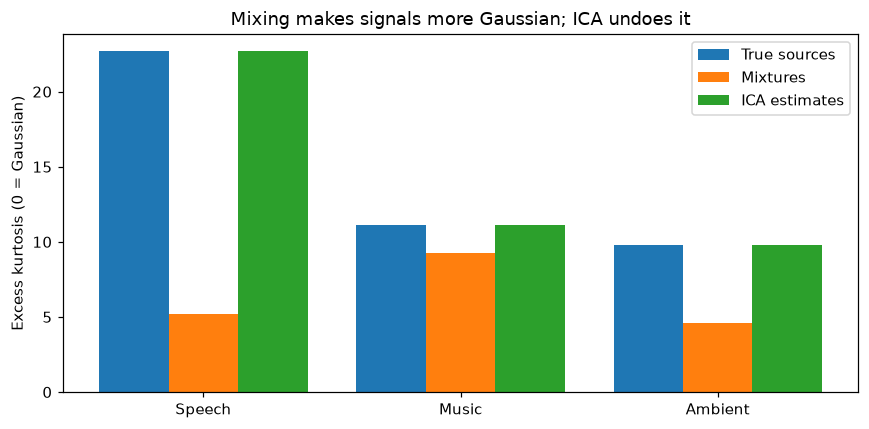

In [6]:
k_src = kurtosis(S, axis=1)
k_mix = kurtosis(X, axis=1)
k_est = kurtosis(S_aligned, axis=1)

x = np.arange(3); w = 0.27
plt.figure(figsize=(8, 4))
plt.bar(x - w, k_src, w, label="True sources")
plt.bar(x,     k_mix, w, label="Mixtures")
plt.bar(x + w, k_est, w, label="ICA estimates")
plt.xticks(x, names); plt.ylabel("Excess kurtosis (0 = Gaussian)")
plt.title("Mixing makes signals more Gaussian; ICA undoes it")
plt.legend(); plt.tight_layout()
plt.savefig("../outputs/figures/kurtosis.png", bbox_inches="tight")
plt.show()

source      |corr|  SI-SDR ICA  SI-SDR mix    gain
speech      1.0000       58.37        2.40   55.97
music       1.0000       41.10        1.88   39.23
ambient     0.9999       38.36       -5.60   43.96


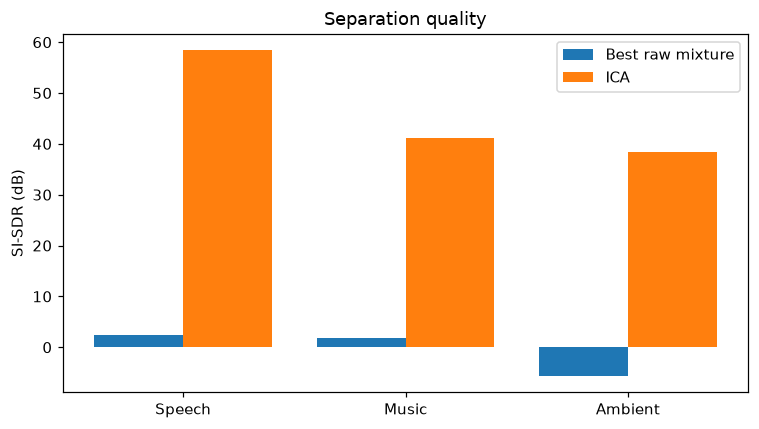

In [7]:
import csv
with open("../outputs/results.csv") as f:
    rows = list(csv.DictReader(f))

print(f"{'source':<9}{'|corr|':>9}{'SI-SDR ICA':>12}{'SI-SDR mix':>12}{'gain':>8}")
for r in rows:
    print(f"{r['source']:<9}{float(r['abs_corr']):>9.4f}{float(r['si_sdr_ica_db']):>12.2f}"
          f"{float(r['si_sdr_best_mixture_db']):>12.2f}{float(r['gain_db']):>8.2f}")

ica = [float(r["si_sdr_ica_db"]) for r in rows]
mix = [float(r["si_sdr_best_mixture_db"]) for r in rows]
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, mix, 0.4, label="Best raw mixture")
plt.bar(x + 0.2, ica, 0.4, label="ICA")
plt.xticks(x, names); plt.ylabel("SI-SDR (dB)"); plt.legend()
plt.title("Separation quality"); plt.tight_layout()
plt.savefig("../outputs/figures/sdr.png", bbox_inches="tight")
plt.show()

In [8]:
from IPython.display import Audio, display
print("Mixture 1:");           display(Audio(X[0] / np.abs(X[0]).max(), rate=SR))
for j, n in enumerate(names):
    print(f"Separated {n}:");  display(Audio(S_aligned[j] / np.abs(S_aligned[j]).max(), rate=SR))

Mixture 1:


Separated Speech:


Separated Music:


Separated Ambient:
